# 05 · Ablações, incerteza e limitações

**Objetivo.** Testar se alguma variante simples “conserta” o teste e quantificar
a incerteza dos resultados. Nenhuma variante é escolhida com base no teste; as
ablations são **descritivas** e servem para delimitar o espaço de soluções.

**Perguntas orientadoras.**

1. Algum peso entre forma e trajetória separa o teste?
2. Normalizações alternativas (ombro, nenhuma) recuperam a forma da mão?
3. Um DTW que ignora blocos invisíveis melhora o ranking?
4. A janela DTW ou o número de frames muda a conclusão?
5. Quão largos são os intervalos de confiança com 6 positivos e 18 negativos?
6. O que é razoável recomendar para o projeto?

**Regra.** O split de validação continua sendo o único usado para escolher
parâmetros. As tabelas de teste existem para diagnóstico e são rotuladas como
tal.

In [1]:
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
EDA_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (EDA_ROOT / "src" / "peter_eda").exists():
    raise RuntimeError(
        "Execute o notebook a partir de eda/ ou eda/notebooks/."
    )
sys.path.insert(0, str(EDA_ROOT / "src"))

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from peter_eda import config, dtw, loaders, manifest, metrics, quality, visualization

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
config.ensure_output_dirs()

dataset = loaders.load_dataset()


def show_paths(paths):
    # Show a mapping of name -> saved file, with the image inline.
    display(pd.Series(paths, name="figura").to_frame())
    for path in paths.values():
        display(Image(filename=str(path)))


print("EDA:", config.EDA_ROOT)
print("Projeto Peter:", config.PROJECT_ROOT)
print("Saídas:", config.OUTPUTS_DIR)

EDA: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda
Projeto Peter: C:\Users\henri\AppData\Local\Temp\opencode\peter_work
Saídas: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs


## 1. Ablação de pesos

Pré-calculamos as matrizes de similaridade de forma e trajetória uma vez e
combinamos com pesos de 0 a 1. O limiar é mantido em 0,68 (default) e 0,76
(ajustado), para separar o efeito do peso do efeito do limiar. O portão de
movimento é 0,04.

In [2]:
tuned = dtw.configuration_from_prior(dataset.prior_results)
matrices = {
    split: dtw.precompute_score_matrices(
        dataset.by_split(split), dataset.templates, tuned
    )
    for split in ("validation", "test")
}

weight_rows = []
for weight in (0.0, 0.25, 0.5, 0.75, 1.0):
    for threshold in (0.68, 0.76):
        for split, matrix in matrices.items():
            trajectory = np.nan_to_num(matrix["trajectory"], nan=0.0)
            combined = weight * matrix["shape"] + (1.0 - weight) * trajectory
            best_scores = combined.max(axis=1)
            predicted = (
                (best_scores >= threshold) & (matrix["motion"] >= tuned.min_motion)
            ).astype(int)
            result = metrics.classification_metrics(matrix["y_true"], predicted)
            roc = metrics.roc_analysis(matrix["y_true"], best_scores)
            weight_rows.append(
                {
                    "peso_forma": weight,
                    "peso_trajetoria": 1.0 - weight,
                    "threshold": threshold,
                    "split": split,
                    "true_positive": result["true_positive"],
                    "false_positive": result["false_positive"],
                    "recall": result["recall"],
                    "specificity": result["specificity"],
                    "balanced_accuracy": result["balanced_accuracy"],
                    "auc": roc["auc"],
                }
            )
weight_table = pd.DataFrame(weight_rows)
weight_table.to_csv(
    config.output_path("table", "weight_ablation.csv"), index=False, encoding="utf-8"
)
display(weight_table.round(3))

,peso_forma,peso_trajetoria,threshold,split,true_positive,false_positive,recall,specificity,balanced_accuracy,auc
0,0.00,1.00,0.68,validation,6,18,1.000,0.000,0.500,1.000
1,0.00,1.00,0.68,test,0,6,0.000,0.667,0.333,0.426
2,0.00,1.00,0.76,validation,6,12,1.000,0.333,0.667,1.000
3,0.00,1.00,0.76,test,0,5,0.000,0.722,0.361,0.426
4,0.25,0.75,0.68,validation,6,10,1.000,0.444,0.722,1.000
5,0.25,0.75,0.68,test,0,2,0.000,0.889,0.444,0.370
6,0.25,0.75,0.76,validation,6,0,1.000,1.000,1.000,1.000
7,0.25,0.75,0.76,test,0,0,0.000,1.000,0.500,0.370
8,0.50,0.50,0.68,validation,6,0,1.000,1.000,1.000,1.000
9,0.50,0.50,0.68,test,0,0,0.000,1.000,0.500,0.324


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\05_ablacao_pesos.png


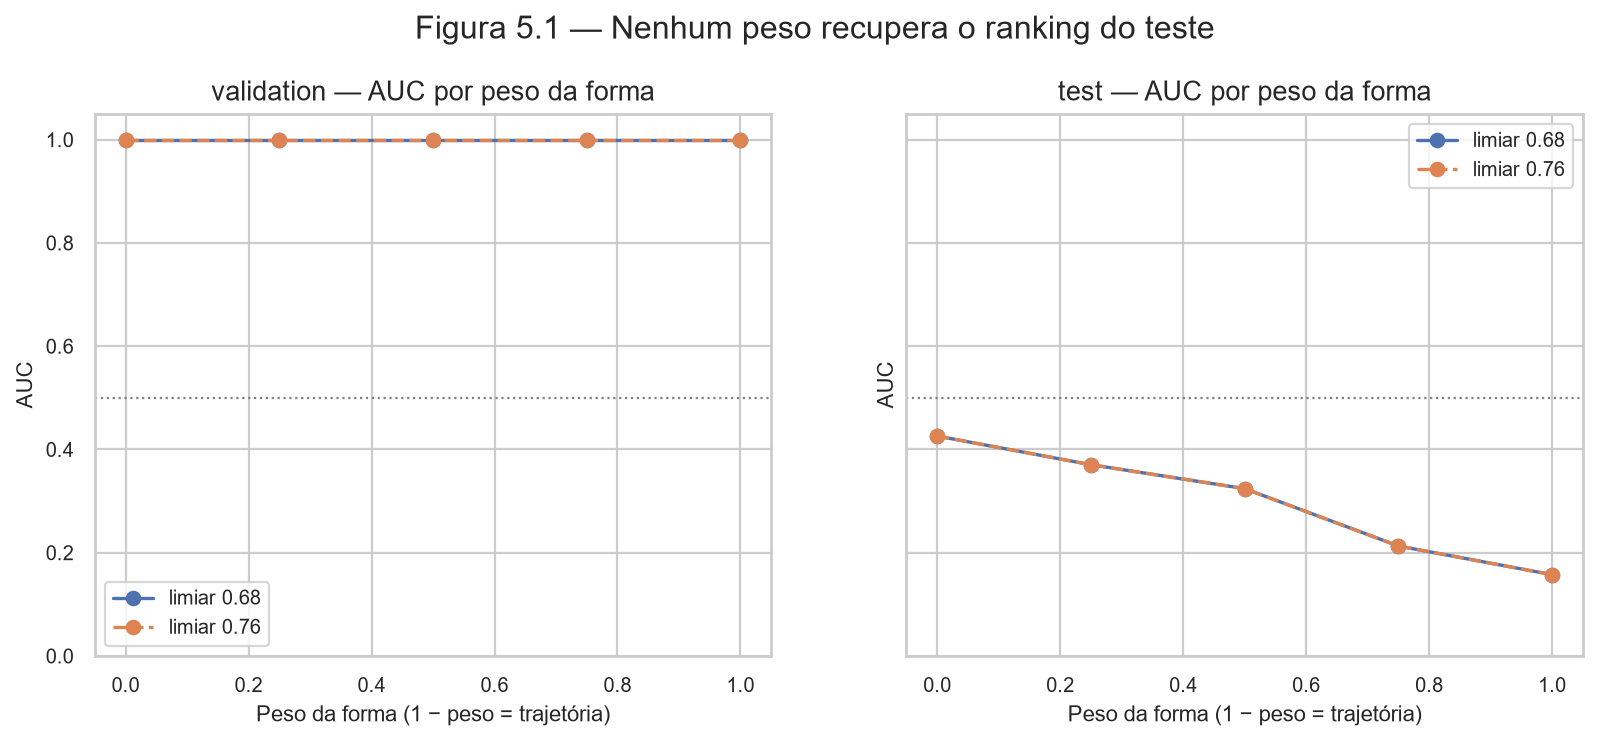

In [3]:
visualization.setup_style()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for axis, split in zip(axes, ("validation", "test")):
    subset = weight_table[weight_table["split"] == split]
    for threshold, style in ((0.68, "-"), (0.76, "--")):
        part = subset[np.isclose(subset["threshold"], threshold)]
        axis.plot(
            part["peso_forma"],
            part["auc"],
            marker="o",
            linestyle=style,
            label=f"limiar {threshold:.2f}",
        )
    axis.axhline(0.5, color="grey", linestyle=":", linewidth=1)
    axis.set_title(f"{split} — AUC por peso da forma")
    axis.set_xlabel("Peso da forma (1 − peso = trajetória)")
    axis.set_ylabel("AUC")
    axis.set_ylim(0.0, 1.05)
    axis.legend(frameon=True)
fig.suptitle("Figura 5.1 — Nenhum peso recupera o ranking do teste", y=1.02)
weight_figure = visualization.save_figure(fig, "05_ablacao_pesos.png")
plt.close(fig)
print("Figura:", weight_figure)
display(Image(filename=str(weight_figure)))

**Leitura.** Na validação, qualquer peso até 0,5 mantém AUC 1,0. No teste, a AUC
fica entre ~0,17 (forma pura) e ~0,44 (trajetória pura), sempre abaixo de 0,5.
Pesos não resolvem: a informação discriminativa de forma simplesmente não está
presente para o informante 5, e a trajetória é praticamente neutra.

O resultado também mostra por que a configuração ajustada escolheu 0,25/0,75:
na validação, dar mais peso à trajetória preserva a separação e aumenta a margem.
No teste, esse mesmo peso faz os negativos `LUZ`/`JA` subirem mais que os
positivos.

## 2. Normalizações alternativas

Além da escala da palma, testamos:

- **ombro:** dividir a forma pela largura dos ombros;
- **nenhuma:** não dividir por escala alguma.

No esqueleto canônico, a distância entre ombros é 1,0. Por isso “ombro” e
“nenhuma” devem produzir resultados idênticos — o que é uma descoberta
metodológica, não um bug.

In [4]:
normalization_rows = []
for scale_mode in ("palm", "shoulder", "none"):
    for split in ("validation", "test"):
        scored = dtw.score_samples(
            dataset.by_split(split),
            dataset.templates,
            tuned,
            shape_scale=scale_mode,
        )
        y_true = (scored["class_name"] == "SIM").astype(int).to_numpy()
        roc = metrics.roc_analysis(y_true, scored["best_score"].to_numpy())
        sweep = metrics.threshold_sweep(y_true, scored["best_score"].to_numpy())
        best = sweep.sort_values("balanced_accuracy", ascending=False).iloc[0]
        positives = scored.loc[scored["class_name"] == "SIM", "best_score"]
        negatives = scored.loc[scored["class_name"] != "SIM", "best_score"]
        normalization_rows.append(
            {
                "normalização": scale_mode,
                "split": split,
                "auc": roc["auc"],
                "melhor_threshold": best["threshold"],
                "melhor_ba": best["balanced_accuracy"],
                "tp_no_melhor": best["true_positive"],
                "fp_no_melhor": best["false_positive"],
                "score_pos_min": positives.min(),
                "score_pos_max": positives.max(),
                "score_neg_min": negatives.min(),
                "score_neg_max": negatives.max(),
            }
        )
normalization_table = pd.DataFrame(normalization_rows)
normalization_table.to_csv(
    config.output_path("table", "normalization_ablation.csv"),
    index=False,
    encoding="utf-8",
)
display(normalization_table.round(3))

,normalização,split,auc,melhor_threshold,melhor_ba,tp_no_melhor,fp_no_melhor,score_pos_min,score_pos_max,score_neg_min,score_neg_max
0,palm,validation,1.00,0.76,1.000,6.0,0.0,0.768,0.857,0.611,0.749
1,palm,test,0.37,0.49,0.667,6.0,12.0,0.500,0.555,0.428,0.687
2,shoulder,validation,1.00,0.81,0.972,6.0,1.0,0.817,0.896,0.636,0.817
3,shoulder,test,0.38,0.53,0.639,6.0,13.0,0.539,0.605,0.461,0.752
4,none,validation,1.00,0.81,0.972,6.0,1.0,0.817,0.896,0.636,0.817
5,none,test,0.38,0.53,0.639,6.0,13.0,0.539,0.605,0.461,0.752


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\05_normalizacao.png


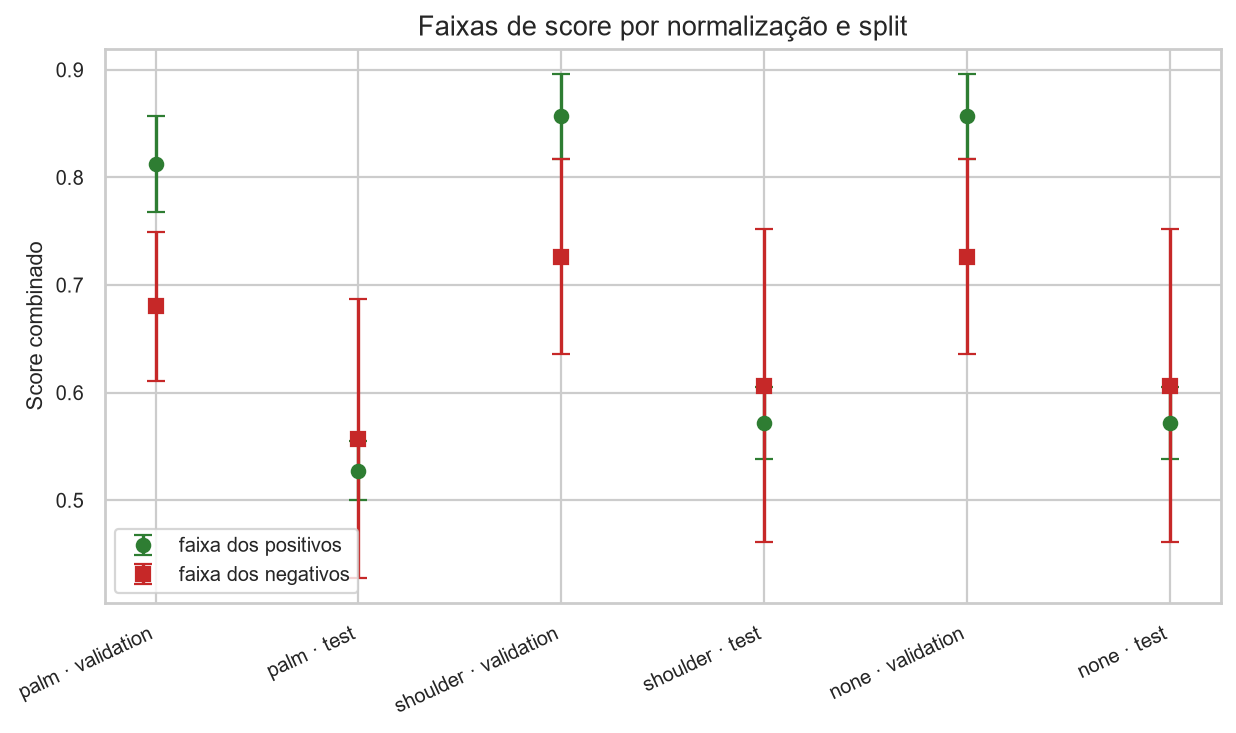

In [5]:
fig, axis = plt.subplots(figsize=(9, 4.5))
plot_data = normalization_table.copy()
plot_data["grupo"] = plot_data["normalização"] + " · " + plot_data["split"]
x = np.arange(len(plot_data))
axis.errorbar(
    x,
    (plot_data["score_pos_min"] + plot_data["score_pos_max"]) / 2,
    yerr=[
        (plot_data["score_pos_max"] - plot_data["score_pos_min"]) / 2,
        (plot_data["score_pos_max"] - plot_data["score_pos_min"]) / 2,
    ],
    fmt="o",
    color="#2E7D32",
    label="faixa dos positivos",
    capsize=4,
)
axis.errorbar(
    x,
    (plot_data["score_neg_min"] + plot_data["score_neg_max"]) / 2,
    yerr=[
        (plot_data["score_neg_max"] - plot_data["score_neg_min"]) / 2,
        (plot_data["score_neg_max"] - plot_data["score_neg_min"]) / 2,
    ],
    fmt="s",
    color="#C62828",
    label="faixa dos negativos",
    capsize=4,
)
axis.set_xticks(x)
axis.set_xticklabels(plot_data["grupo"], rotation=25, ha="right")
axis.set_ylabel("Score combinado")
axis.set_title("Faixas de score por normalização e split")
axis.legend(frameon=True)
normalization_figure = visualization.save_figure(fig, "05_normalizacao.png")
plt.close(fig)
print("Figura:", normalization_figure)
display(Image(filename=str(normalization_figure)))

**Leitura.** “Ombro” e “nenhuma” são numericamente idênticos (AUC 0,380 no
teste), confirmando que o esqueleto canônico já está normalizado pelos ombros.
A escala da palma é a única normalização com efeito real, e sua AUC de teste é
0,370 — ligeiramente pior que não normalizar (0,380). Nenhuma escolha recupera a
separação: no melhor limiar, todas produzem muitos falsos positivos (12–13).

A normalização, portanto, não é a alavanca que falta. O problema está na
representação de forma em si, que não é invariante à identidade do informante.

## 3. DTW com máscara de visibilidade

O DTW de produção compara todos os 168 dimensões, inclusive posições de
articulações invisíveis que foram zeradas. A variante abaixo ignora blocos
invisíveis e calcula o custo apenas nos blocos visíveis em ambos os frames.

Isso é um experimento, **não** o algoritmo de produção. A pergunta é se a
ausência de mão (não a geometria) estava dominando a distância.

In [6]:
masked_rows = []
for split in ("validation", "test"):
    scored = dtw.score_samples(
        dataset.by_split(split), dataset.templates, tuned, masked=True
    )
    y_true = (scored["class_name"] == "SIM").astype(int).to_numpy()
    roc = metrics.roc_analysis(y_true, scored["best_score"].to_numpy())
    sweep = metrics.threshold_sweep(y_true, scored["best_score"].to_numpy())
    best = sweep.sort_values("balanced_accuracy", ascending=False).iloc[0]
    positives = scored.loc[scored["class_name"] == "SIM", "best_score"]
    negatives = scored.loc[scored["class_name"] != "SIM", "best_score"]
    masked_rows.append(
        {
            "split": split,
            "auc": roc["auc"],
            "melhor_threshold": best["threshold"],
            "melhor_ba": best["balanced_accuracy"],
            "tp_no_melhor": best["true_positive"],
            "fp_no_melhor": best["false_positive"],
            "score_pos_min": positives.min(),
            "score_pos_max": positives.max(),
            "score_neg_min": negatives.min(),
            "score_neg_max": negatives.max(),
        }
    )
masked_table = pd.DataFrame(masked_rows)
masked_table.to_csv(
    config.output_path("table", "masked_dtw_ablation.csv"),
    index=False,
    encoding="utf-8",
)
display(masked_table.round(3))

,split,auc,melhor_threshold,melhor_ba,tp_no_melhor,fp_no_melhor,score_pos_min,score_pos_max,score_neg_min,score_neg_max
0,validation,0.167,0.30,0.500,6.0,18.0,0.954,1.0,1.000,1.0
1,test,0.574,0.95,0.639,5.0,10.0,0.854,1.0,0.867,1.0


**Leitura.** A máscara satura os scores: negativos de validação chegam a 1,0 e a
AUC de validação cai para 0,167 (inversão). No teste, a AUC sobe para 0,574, mas
o melhor ponto operacional ainda tem 10 falsos positivos para 5 verdadeiros
positivos (de 6). A máscara remove informação útil junto com o ruído: quando
quase todos os blocos são visíveis, ignorar os poucos invisíveis não separa as
classes.

A hipótese 2 também não se sustenta como solução.

## 4. Sensibilidade à janela DTW

A banda de Sakoe-Chiba controla o quanto o alinhamento pode “torcer”. Testamos
0,10, 0,28 (produção) e 0,50, mantendo o restante da configuração ajustada.

In [7]:
window_rows = []
for ratio in (0.10, 0.28, 0.50):
    configuration = config.MatchConfiguration(
        name=f"window-{ratio:.2f}",
        threshold=tuned.threshold,
        min_motion=tuned.min_motion,
        hand_shape_weight=tuned.hand_shape_weight,
        hand_trajectory_weight=tuned.hand_trajectory_weight,
        window_ratio=ratio,
        max_frames=tuned.max_frames,
    )
    for split in ("validation", "test"):
        scored, result = dtw.evaluate_configuration(
            dataset.by_split(split), dataset.templates, configuration
        )
        roc = metrics.roc_analysis(
            (scored["class_name"] == "SIM").astype(int), scored["best_score"]
        )
        window_rows.append(
            {
                "janela": ratio,
                "split": split,
                "auc": roc["auc"],
                "true_positive": result["true_positive"],
                "false_positive": result["false_positive"],
                "balanced_accuracy": result["balanced_accuracy"],
            }
        )
window_table = pd.DataFrame(window_rows)
window_table.to_csv(
    config.output_path("table", "window_ablation.csv"), index=False, encoding="utf-8"
)
display(window_table.round(3))

,janela,split,auc,true_positive,false_positive,balanced_accuracy
0,0.10,validation,1.000,5,0,0.917
1,0.10,test,0.398,0,0,0.500
2,0.28,validation,1.000,6,0,1.000
3,0.28,test,0.370,0,0,0.500
4,0.50,validation,1.000,6,0,1.000
5,0.50,test,0.370,0,0,0.500


**Leitura.** A janela de produção (0,28) não é a causa: 0,10 e 0,50 produzem o
mesmo 0/6 no teste e AUC 0,370–0,398. A janela estreita perde um positivo na
validação (5/6), mas não muda a conclusão. O problema não está no alinhamento
temporal.

## 5. Incerteza com amostras pequenas

Com 6 positivos e 18 negativos, proporções como “6/6” e “0/6” são instáveis.
Reportamos intervalos de Wilson de 95% para recall e especificidade, e bootstrap
estratificado para a AUC. O bootstrap não corrige o desenho; apenas mostra a
sensibilidade à amostra.

In [8]:
uncertainty_rows = []
for split in ("validation", "test"):
    scored, result = dtw.evaluate_configuration(
        dataset.by_split(split), dataset.templates, tuned
    )
    y_true = (scored["class_name"] == "SIM").astype(int).to_numpy()
    positives = int((y_true == 1).sum())
    negatives = int((y_true == 0).sum())
    recall_low, recall_high = metrics.wilson_interval(result["true_positive"], positives)
    specificity_low, specificity_high = metrics.wilson_interval(
        result["true_negative"], negatives
    )
    auc_ci = metrics.bootstrap_auc_ci(
        y_true, scored["best_score"].to_numpy(), n_bootstrap=2000, seed=2026
    )
    uncertainty_rows.append(
        {
            "split": split,
            "positivos": positives,
            "negativos": negatives,
            "recall": result["recall"],
            "recall_ic95_inf": recall_low,
            "recall_ic95_sup": recall_high,
            "especificidade": result["specificity"],
            "especificidade_ic95_inf": specificity_low,
            "especificidade_ic95_sup": specificity_high,
            "auc": metrics.roc_analysis(y_true, scored["best_score"])["auc"],
            "auc_ic95_inf": auc_ci["low"],
            "auc_ic95_sup": auc_ci["high"],
        }
    )
uncertainty_table = pd.DataFrame(uncertainty_rows)
uncertainty_table.to_csv(
    config.output_path("table", "uncertainty.csv"), index=False, encoding="utf-8"
)
display(uncertainty_table.round(3))

,split,positivos,negativos,recall,recall_ic95_inf,recall_ic95_sup,especificidade,especificidade_ic95_inf,especificidade_ic95_sup,auc,auc_ic95_inf,auc_ic95_sup
0,validation,6,18,1.0,0.61,1.00,1.0,0.824,1.0,1.00,1.000,1.000
1,test,6,18,0.0,0.00,0.39,1.0,0.824,1.0,0.37,0.167,0.593


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\05_incerteza.png


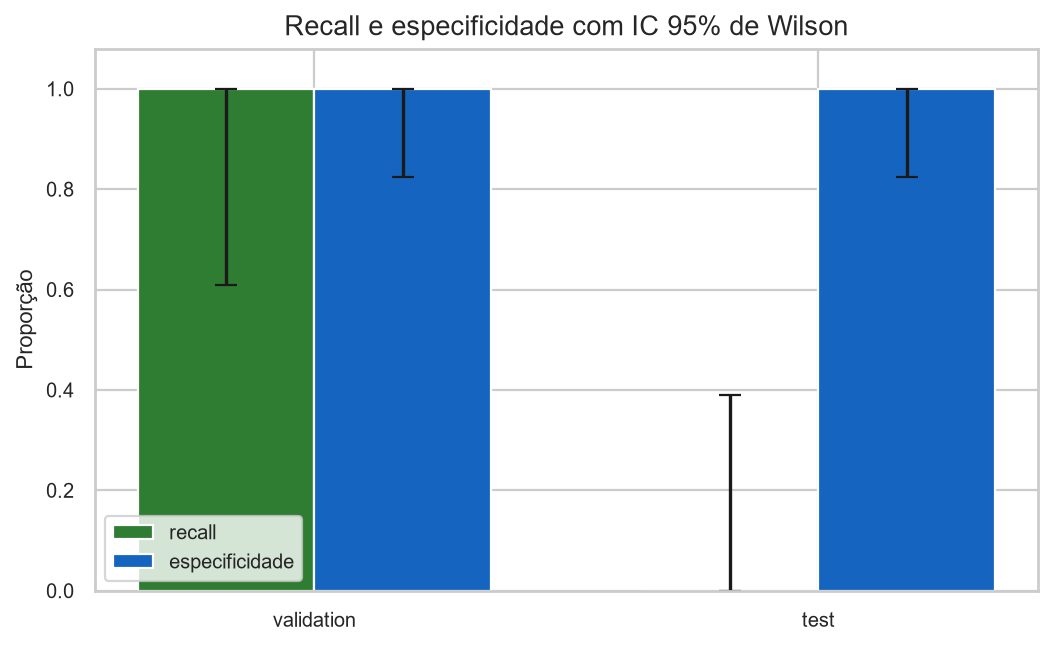

In [9]:
fig, axis = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(uncertainty_table))
width = 0.35

recall_error = [
    (uncertainty_table["recall"] - uncertainty_table["recall_ic95_inf"]).clip(lower=0),
    (uncertainty_table["recall_ic95_sup"] - uncertainty_table["recall"]).clip(lower=0),
]
specificity_error = [
    (uncertainty_table["especificidade"] - uncertainty_table["especificidade_ic95_inf"]).clip(lower=0),
    (uncertainty_table["especificidade_ic95_sup"] - uncertainty_table["especificidade"]).clip(lower=0),
]

axis.bar(
    x - width / 2,
    uncertainty_table["recall"],
    width,
    yerr=recall_error,
    capsize=5,
    label="recall",
    color="#2E7D32",
)
axis.bar(
    x + width / 2,
    uncertainty_table["especificidade"],
    width,
    yerr=specificity_error,
    capsize=5,
    label="especificidade",
    color="#1565C0",
)
axis.set_xticks(x)
axis.set_xticklabels(uncertainty_table["split"])
axis.set_ylim(0, 1.08)
axis.set_ylabel("Proporção")
axis.set_title("Recall e especificidade com IC 95% de Wilson")
axis.legend(frameon=True)
uncertainty_figure = visualization.save_figure(fig, "05_incerteza.png")
plt.close(fig)
print("Figura:", uncertainty_figure)
display(Image(filename=str(uncertainty_figure)))

**Leitura.** O recall de validação 6/6 tem IC 95% de ~0,61–1,00; o recall de
teste 0/6 tem IC ~0,00–0,39. A especificidade de teste 18/18 tem IC ~0,82–1,00.
Ou seja: “0/6 no teste” é compatível com um recall verdadeiro de até ~39%, e
“6/6 na validação” é compatível com um recall verdadeiro a partir de ~61%. Os
dois resultados **não são estatisticamente incompatíveis** com um modelo
mediocre; o que os distingue é a AUC, que usa a ordenação e cai para 0,37.

Com n = 6, qualquer conclusão sobre “acurácia perfeita” deve ser tratada como
hipótese, não como estimativa precisa.

## 6. Tabela consolidada de achados

A tabela reúne as evidências principais em formato adequado a um relatório
técnico. Ela é salva em `outputs/tables/findings_summary.csv`.

In [10]:
parity = dtw.parity_with_prior_results(dataset)
parity_max = float(parity["absolute_delta"].max())

findings = pd.DataFrame(
    [
        {
            "achado": "Paridade Python–TypeScript",
            "evidência": f"delta máximo {parity_max:.2e} em 72 pares de teste",
            "implicação": "a análise usa o algoritmo real, não uma aproximação",
        },
        {
            "achado": "Validação perfeitamente separável",
            "evidência": "6/6 positivos, 0 FP, AUC 1,0",
            "implicação": "validação fácil demais; não representa o teste",
        },
        {
            "achado": "Teste sem reconhecimento",
            "evidência": "0/6 positivos, 0 FP, AUC 0,370",
            "implicação": "falha de ranking, não de limiar",
        },
        {
            "achado": "Melhor limiar possível no teste",
            "evidência": "threshold 0,49 → 6 TP e 12 FP",
            "implicação": "não existe ponto de operação com alta sensibilidade e especificidade",
        },
        {
            "achado": "Forma da mão é o componente frágil",
            "evidência": "AUC 0,167 no teste vs 1,0 na validação",
            "implicação": "a representação de forma não é invariante ao informante",
        },
        {
            "achado": "Cobertura não explica",
            "evidência": "teste tem handCoverage ~0,98; SIM = 1,0",
            "implicação": "não é oclusão; é geometria",
        },
        {
            "achado": "Informante 5 é OOD",
            "evidência": "distância média teste SIM × treino ~5,4 vs validação ~2,4",
            "implicação": "o split de teste mede generalização cross-informant",
        },
        {
            "achado": "Pesos não corrigem",
            "evidência": "AUC de teste 0,17–0,44 em todos os pesos",
            "implicação": "não há combinação linear que recupere o ranking",
        },
        {
            "achado": "Normalização não corrige",
            "evidência": "ombro ≡ nenhuma; AUC de teste 0,37–0,38",
            "implicação": "o esqueleto já é normalizado pelos ombros",
        },
        {
            "achado": "Máscara de visibilidade não corrige",
            "evidência": "AUC de teste 0,574, mas 10 FP no melhor ponto",
            "implicação": "ignorar blocos invisíveis remove sinal junto com ruído",
        },
        {
            "achado": "Janela DTW não corrige",
            "evidência": "0/6 no teste para janelas 0,10/0,28/0,50",
            "implicação": "o alinhamento temporal não é o gargalo",
        },
        {
            "achado": "Amostra pequena",
            "evidência": "recall de teste IC95% ~0,00–0,39",
            "implicação": "resultados são hipóteses, não estimativas precisas",
        },
    ]
)
findings.to_csv(
    config.output_path("table", "findings_summary.csv"), index=False, encoding="utf-8"
)
display(findings)

,achado,evidência,implicação
0,Paridade Python–TypeScript,delta máximo 2.22e-16 em 72 pares de teste,"a análise usa o algoritmo real, não uma aproximação"
1,Validação perfeitamente separável,"6/6 positivos, 0 FP, AUC 1,0",validação fácil demais; não representa o teste
2,Teste sem reconhecimento,"0/6 positivos, 0 FP, AUC 0,370","falha de ranking, não de limiar"
3,Melhor limiar possível no teste,"threshold 0,49 → 6 TP e 12 FP",não existe ponto de operação com alta sensibilidade e especificidade
4,Forma da mão é o componente frágil,"AUC 0,167 no teste vs 1,0 na validação",a representação de forma não é invariante ao informante
5,Cobertura não explica,"teste tem handCoverage ~0,98; SIM = 1,0",não é oclusão; é geometria
6,Informante 5 é OOD,"distância média teste SIM × treino ~5,4 vs validação ~2,4",o split de teste mede generalização cross-informant
7,Pesos não corrigem,"AUC de teste 0,17–0,44 em todos os pesos",não há combinação linear que recupere o ranking
8,Normalização não corrige,"ombro ≡ nenhuma; AUC de teste 0,37–0,38",o esqueleto já é normalizado pelos ombros
9,Máscara de visibilidade não corrige,"AUC de teste 0,574, mas 10 FP no melhor ponto",ignorar blocos invisíveis remove sinal junto com ruído


## 7. Recomendações

1. **Não ajustar limiar no teste.** O melhor limiar possível no teste ainda tem
   12 falsos positivos; escolhê-lo seria overfitting ao split de avaliação.
2. **Avaliar por informante, com validação agrupada.** O protocolo atual usa um
   único informante na validação e outro no teste. Um leave-one-informant-out
   com os informantes disponíveis daria uma estimativa mais honesta da
   variabilidade.
3. **Coletar mais informantes para o treino.** Com três informantes, o modelo de
   template não tem como cobrir a variabilidade de forma da mão.
4. **Investir em invariância à forma.** Normalização por pose da mão, aumento de
   dados com rotações/espelhamentos ou features geométricas invariantes são
   direções mais promissoras que ajustar pesos.
5. **Separar “SIM” de “não-SIM” de forma explícita.** Hoje todos os templates
   têm o mesmo gloss e a margem é inerte. Um classificador binário com negativos
   de treino permitiria calibrar de verdade.
6. **Reportar incerteza.** Com 6 positivos por split, qualquer número deve vir
   com intervalo; 6/6 e 0/6 não são estimativas estáveis.

## 8. Limitações gerais

- O ZIP não contém os vídeos originais; não é possível separar erro de extração
  de variação real de execução.
- Os rótulos de informante são locais por item; a conclusão de “informante 5
  OOD” depende dessa rotulagem.
- O teste tem apenas 24 amostras e um único informante; a AUC tem IC largo.
- As ablations são descritivas e não constituem uma busca exaustiva de
  arquiteturas.
- A máscara de visibilidade é uma variante experimental; seus resultados não
  devem ser comparados diretamente ao runtime de produção.
- A conclusão principal — mudança de distribuição — é compatível com os dados,
  mas não prova causalidade. Um experimento controlado com novos informantes
  seria necessário para isso.